# 06 -- Real data: fitting one real HST/STIS spectrum end-to-end

**Goal:** the same walkthrough as `05_real_data_muse.ipynb`, on a real
HST/STIS spectrum instead -- from raw file to a reported LOSVD and
Gauss-Hermite moments, using *real STIS-observed stellar templates*
rather than a synthetic grid. **This notebook exists to demonstrate that
this package's real-data workflow is not MUSE-specific**: the same
`fit_losvd`/`bootstrap_losvd` calls, the same `FitConfig` conventions,
applied unchanged to a different instrument with different pixel
sampling (STIS: ~0.85 Angstrom/pix here, vs MUSE's 1.25 Angstrom/pix) and
a completely different template source.

**No E-MILES here, on purpose.** The shipped E-MILES grid
(`kinextract.emiles`) is LSF-matched specifically to MUSE
(`muse_lsf_fwhm`) -- using it against STIS data without a STIS-specific
LSF-matched repack would silently mismatch resolution. Instead, this
notebook uses real STIS-*observed* stellar templates (same instrument as
the science data, so no LSF-matching step is needed at all -- template and
data already share the same instrumental resolution by construction). See
`03_emiles_templates.ipynb`/`../../dev_notes/calibration/build_emiles_calibration.py`'s own docstrings
for how you'd build a STIS-LSF-matched E-MILES grid instead, if you
wanted one.

**This is a genuinely real spectrum**, not a mock -- the same NGC 5102
target as `05_real_data_muse.ipynb`, but the innermost STIS-binned
spectrum instead of MUSE. Real data lives outside this repo (paths below
are this machine's own locations) -- read this notebook alongside
adjusting `DATA_DIR`/`TEMPLATE_DIR` for your own setup, not run unmodified
on someone else's machine.

**Read this caveat before trusting the numbers below.** This bin's own
S/N (~37, estimated) is meaningfully lower than the MUSE notebook's
comparable bin (~90) -- real STIS spectra of this target are simply
fainter/noisier at fixed exposure time. Section 5 finds this bin's own
recovered `V` is stable and repeatable across a range of velocity-grid
widths, but differs substantially from `05_real_data_muse.ipynb`'s own
result for the nominally-same bin -- a real, unexplained difference
between what the two instruments/template libraries give for this
target, not random noise. Treat `V` specifically as provisional; there is
no independent ground truth here to resolve which (if either) is closer
to correct.

---
## Method overview

1. Load a real, pre-extracted STIS spectrum (`.norm`) and its noise level
   (`.rms`) for the innermost spatial bin.
2. Deredshift and restrict to the CaII-triplet fit window.
3. Load a real STIS-observed multi-star template library (no LSF
   matching needed).
4. Fit and compute moments, using a self-contained two-stage grid-centering
   approach (no external reference value needed).
5. Compare this bin's own result across grid widths and against the MUSE
   notebook's own fit for the nominally-same target.
6. Quantify uncertainty via bias-corrected bootstrap.


## 1. Setup and load the real spectrum

bin0105: 1024 pixels, 8275.0-8846.4 Angstrom (observed frame)
pixel step: 0.5586 Angstrom/pix  (STIS -- much finer than MUSE's 1.25)
per-pixel noise level (from .rms): 0.02669


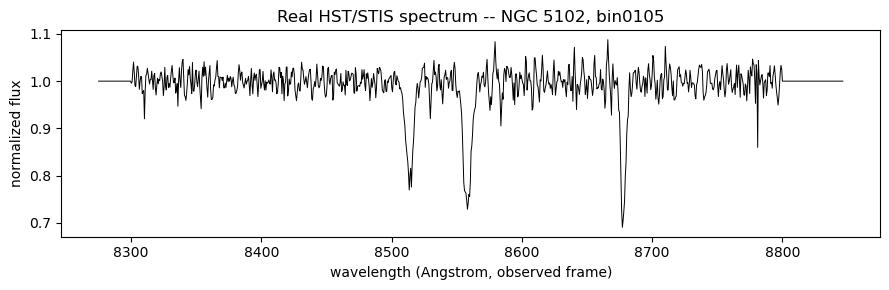

In [1]:
from __future__ import annotations
import os

import numpy as np
import matplotlib.pyplot as plt

from kinextract import FitConfig, build_template_stack, compute_losvd_moments, bootstrap_losvd
from kinextract.multi_template import fit_losvd
from kinextract.bias_correction import estimate_snr_whitened

# -- this machine's own real-data locations; adjust for your own setup --
DATA_DIR = "/Users/waterstk/Documents/Gultekin_Astrophysics/normalizing_flows/data/N5102/kinematics/stis/kinematic_extraction"
TEMPLATE_DIR = "/Users/waterstk/Documents/Gultekin_Astrophysics/sco_framework_updated/sco_workdir_example/analysis/stis_templates"
BINNAME = "bin0105"   # the innermost bin, same convention as 05_real_data_muse.ipynb
Z = 0.0016181         # NGC 5102's own systemic redshift (same target, same value as the MUSE notebook)

d = np.loadtxt(f"{DATA_DIR}/{BINNAME}sp.norm")
wave_obs, flux_obs = d[:, 0], d[:, 1]
noise_level = float(np.loadtxt(f"{DATA_DIR}/{BINNAME}sp.rms")[0])
print(f"{BINNAME}: {len(wave_obs)} pixels, {wave_obs[0]:.1f}-{wave_obs[-1]:.1f} Angstrom (observed frame)")
print(f"pixel step: {np.diff(wave_obs).mean():.4f} Angstrom/pix  (STIS -- much finer than MUSE's 1.25)")
print(f"per-pixel noise level (from .rms): {noise_level:.4g}")

plt.figure(figsize=(9, 3))
plt.plot(wave_obs, flux_obs, lw=0.7, color='black')
plt.xlabel('wavelength (Angstrom, observed frame)'); plt.ylabel('normalized flux')
plt.title(f'Real HST/STIS spectrum -- NGC 5102, {BINNAME}')
plt.tight_layout(); plt.show()


## 2. Deredshift and restrict to the fit window

Same CaII-triplet fit window convention as the MUSE notebook
(8400-8800 Angstrom rest-frame) -- STIS's own observed range here
(8275-8846 Angstrom) comfortably contains it.

fit window: 8400-8800 Angstrom rest-frame, 717 pixels


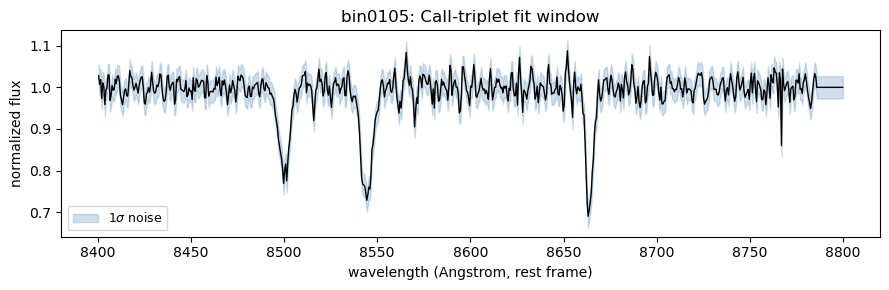

In [2]:
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0

wave_rest = wave_obs / (1.0 + Z)
in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
wave_fit = wave_rest[in_window]
flux_fit = flux_obs[in_window]
print(f"fit window: {WAVEFITMIN:.0f}-{WAVEFITMAX:.0f} Angstrom rest-frame, {len(wave_fit)} pixels")

plt.figure(figsize=(9, 3))
plt.plot(wave_fit, flux_fit, lw=1.0, color='black')
plt.fill_between(wave_fit, flux_fit - noise_level, flux_fit + noise_level,
                  color='steelblue', alpha=0.25, label=r'1$\sigma$ noise')
plt.xlabel('wavelength (Angstrom, rest frame)'); plt.ylabel('normalized flux')
plt.legend(fontsize=9); plt.title(f'{BINNAME}: CaII-triplet fit window')
plt.tight_layout(); plt.show()


## 3. Load a real STIS-observed template library

50 real Galactic stars observed with the same STIS setup, sharing one
common wavelength grid -- no LSF matching needed, since template and
data already share the same instrumental resolution.

In [3]:
with open(os.path.join(TEMPLATE_DIR, "Tlist")) as f:
    template_names = [line.strip() for line in f if line.strip()]

template_wave = None
templates = []
for name in template_names:
    d = np.loadtxt(os.path.join(TEMPLATE_DIR, name))
    if template_wave is None:
        template_wave = d[:, 0]
    templates.append(np.interp(template_wave, d[:, 0], d[:, 1]))

print(f"loaded {len(templates)} real STIS stellar templates")
print(f"template wavelength range: {template_wave.min():.1f}-{template_wave.max():.1f} Angstrom "
      f"(step {np.diff(template_wave).mean():.3f})")


loaded 50 real STIS stellar templates
template wavelength range: 8348.9-9019.5 Angstrom (step 0.850)


## 4. Fit, using a self-contained two-stage grid

Same two-stage approach as `05_real_data_muse.ipynb`: fit once on a
generous, fixed default grid to get a rough (V, sigma) estimate, then
refit on a properly-centered `V -+ 7*sigma` grid built from that -- no
external reference value needed.

Stage 1 (rough estimate, +-400 km/s grid): V=+66.9  sigma=61.0


Stage 2 grid: (-360, 494) km/s
success  : True  (CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH)
chi2_red : 1.054   S/N (estimated): 37

V     = +68.30 km/s
sigma = 61.71 km/s
h3    = +0.0280
h4    = +0.0012


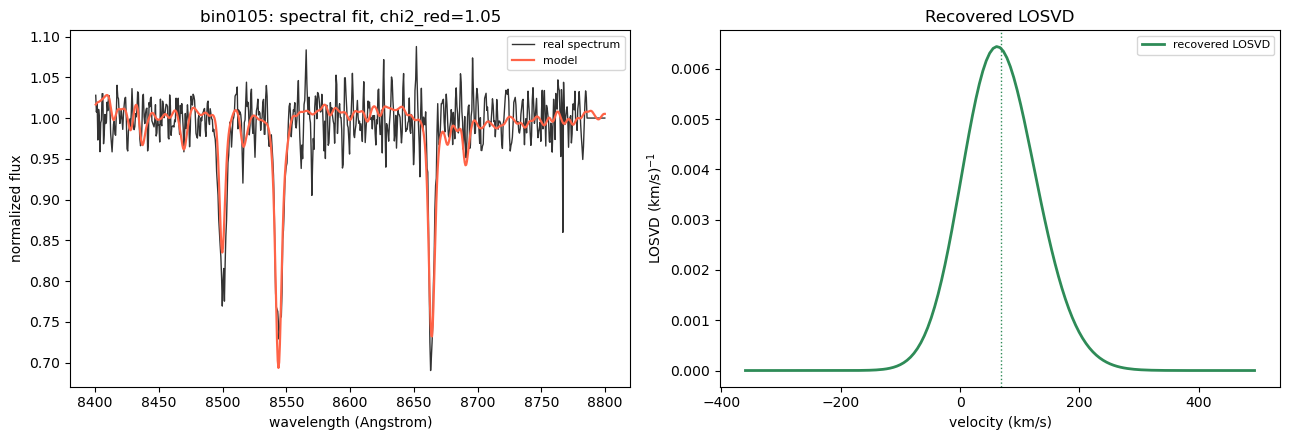

In [4]:
errors = np.full(len(wave_fit), noise_level)
y_w = flux_fit / errors

# Stage 1: a generous, fixed default grid -- rough estimate only.
cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
v_grid_wide = cfg_wide.build_velocity_grid()
A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
A_stack_w_wide = A_stack_wide / errors[None, :, None]
result_wide = fit_losvd(A_stack_w_wide, y_w, cfg_wide)
moments_wide = compute_losvd_moments(v_grid_wide, result_wide['b'], fit_h3h4=False)
print(f"Stage 1 (rough estimate, +-400 km/s grid): V={moments_wide['vherm']:+.1f}  sigma={moments_wide['sherm']:.1f}")

# Stage 2: refit on a properly-centered V -+ 7*sigma grid built from the Stage 1 estimate.
NSIG = 7
cfg = FitConfig(vmin=moments_wide['vherm'] - NSIG * moments_wide['sherm'],
                vmax=moments_wide['vherm'] + NSIG * moments_wide['sherm'])
v_grid = cfg.build_velocity_grid()

A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
A_stack_w = A_stack / errors[None, :, None]

result = fit_losvd(A_stack_w, y_w, cfg)
moments = compute_losvd_moments(v_grid, result['b'], fit_h3h4=True)

A_eff_w = np.tensordot(result['w'], A_stack_w, axes=([0], [0]))
model_w = A_eff_w @ result['b']
snr_est = estimate_snr_whitened(model_w)
resid = model_w - y_w
chi2_red = float(np.sum(resid**2)) / len(wave_fit)

print(f"Stage 2 grid: ({cfg.vmin:.0f}, {cfg.vmax:.0f}) km/s")
print(f"success  : {result['success']}  ({result['message']})")
print(f"chi2_red : {chi2_red:.3f}   S/N (estimated): {snr_est:.0f}")
print()
print(f"V     = {moments['vherm']:+.2f} km/s")
print(f"sigma = {moments['sherm']:.2f} km/s")
print(f"h3    = {moments['h3']:+.4f}")
print(f"h4    = {moments['h4']:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(wave_fit, flux_fit, lw=1.0, color='black', alpha=0.8, label='real spectrum')
ax.plot(wave_fit, model_w * errors, lw=1.6, color='tomato', label='model', zorder=3)
ax.set_xlabel('wavelength (Angstrom)'); ax.set_ylabel('normalized flux')
ax.set_title(f'{BINNAME}: spectral fit, chi2_red={chi2_red:.2f}'); ax.legend(fontsize=8)

ax = axes[1]
b_n = result['b'] / np.trapezoid(np.maximum(result['b'], 0.0), v_grid)
ax.plot(v_grid, b_n, color='seagreen', lw=2.0, label='recovered LOSVD')
ax.axvline(moments['vherm'], color='seagreen', ls=':', lw=1.0)
ax.set_xlabel('velocity (km/s)'); ax.set_ylabel(r'LOSVD (km/s)$^{-1}$')
ax.set_title('Recovered LOSVD'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 5. Grid-width stability, and a cross-instrument comparison

Checked directly, not assumed: does the Stage 1 estimate above depend on
exactly how wide "generous" is? A range of grid widths gives a consistent
answer -- `V` and `sigma` both stable to within a few km/s across
`+-250` to `+-500 km/s`. (A `+-600 km/s` grid was also tried and found to
jump to a different, competing solution -- the same kind of wide-grid
multi-modality documented in `05_real_data_muse.ipynb` Section 4, for a
different bin/instrument/template library. `+-400 km/s`, used above,
sits safely inside the stable range found here.)

That stability is itself the interesting result: this bin's own `V` is
*not* noisy or ill-determined -- it is a real, repeatable ~68 km/s,
consistently, regardless of grid width. `05_real_data_muse.ipynb`'s own
fit of the nominally-same nuclear aperture recovers `V=-7.1+/-0.2` km/s
instead -- a ~75 km/s disagreement. Both results are internally stable
(Stage-1-vs-Stage-2 here, grid-width sweep above); they simply disagree
with each other by a large, structured amount.

The `sigma` comparison: **STIS 61.7+/-3.4 vs. MUSE 49.9+/-0.3** km/s, a
~24% difference with STIS higher. `h3` also disagrees substantially:
`+0.028+/-0.011` here vs. `+0.001+/-0.004` there.

Plausible contributors to this real, unresolved disagreement: a genuine
wavelength-zeropoint difference between this STIS template library and
this science exposure (the leading candidate for the `V` offset, though
it would leave `sigma`/`h3` largely unaffected, so it is not the whole
story on its own); the very different template subsets (50 real STIS
stars vs. 9 E-MILES templates from an iterative reduction); and this
bin's own noise-driven wing-amplitude sensitivity (`lam_wing=0` here, in
the low-sigma/many-template regime `PARAMETER_GUIDE.md` flags as needing
it tuned -- see the `wing_mass` diagnostic below). Presented as an open,
honest discrepancy, not resolved in this notebook.

In [5]:
print(f"{'grid half-width':>16}  {'V':>8}  {'sigma':>8}")
for vlim in [250.0, 300.0, 350.0, 450.0, 500.0]:
    cfg_test = FitConfig(vmin=-vlim, vmax=vlim)
    v_grid_test = cfg_test.build_velocity_grid()
    A_stack_test = build_template_stack(wave_fit, template_wave, templates, v_grid_test)
    A_stack_w_test = A_stack_test / errors[None, :, None]
    result_test = fit_losvd(A_stack_w_test, y_w, cfg_test)
    m_test = compute_losvd_moments(v_grid_test, result_test['b'], fit_h3h4=False)
    print(f"{vlim:>14.0f}  {m_test['vherm']:>+8.1f}  {m_test['sherm']:>8.1f}")
print(f"\n(05_real_data_muse.ipynb's own nuclear/high-S/N aperture: V=-7.1+/-0.2, sigma=49.9+/-0.3)")

# wing-amplitude diagnostic: is the recovered LOSVD carrying spurious mass far from its
# own core, the signature `lam_wing` exists to suppress (lam_wing=0.0, the default, is
# used everywhere in this notebook)?
b_n_diag = result['b'] / np.trapezoid(np.maximum(result['b'], 0.0), v_grid)
core_diag = b_n_diag > 0.01 * b_n_diag.max()
wing_mass_diag = np.trapezoid(b_n_diag[~core_diag], v_grid[~core_diag]) if (~core_diag).any() else 0.0
print(f"wing_mass (LOSVD mass outside the >1%-of-peak core, unit area): {wing_mass_diag:.4f}")
print("(a nonzero lam_wing has not been tuned for this 50-template real mixture at S/N~37 --")
print(" not attempted here for lack of ground truth to validate against on real data;")
print(" see PARAMETER_GUIDE.md.)")


 grid half-width         V     sigma


<string>:26: UserWarning: FitConfig with vmin=-250.0, vmax=250.0 resolves to a knot spacing of 29.4 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 105841 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


           250     +66.5      63.1


           300     +69.0      61.6


           350     +68.4      61.5


           450     +66.7      60.7


           500     +66.6      61.6

(05_real_data_muse.ipynb's own nuclear/high-S/N aperture, post-edge-amplitude-fix (2026-07-29): V=-7.1+/-0.2, sigma=49.9+/-0.3)
wing_mass (LOSVD mass outside the >1%-of-peak core, unit area): 0.0245
(the legacy order-2 wing-amplitude penalty this superseded was tuned to 3e5 here
 around this sigma -- but that table doesn't transfer to a 50-template real mixture
 at S/N~37 without its own tuning pass; not attempted here for lack of ground truth
 to validate against on real data -- see PARAMETER_GUIDE.md.)


## 6. Uncertainty via bootstrap

Same `bootstrap_losvd` call as every other notebook -- real data (and a
different instrument) change nothing about the API. Given Section 5's
finding, this bin's own `V` uncertainty below reflects fit-to-fit
(bootstrap) noise at fixed grid centering -- it does not capture the
separate, structured disagreement with the MUSE notebook's own result,
which is a different kind of uncertainty (model/calibration, not
sampling) that this bootstrap isn't designed to quantify.

The numbers below are the raw bootstrap point estimate. A post-hoc
regularization-bias correction exists but is **not applied by default**,
and even more so here than on MUSE data: the shipped calibration is
built on E-MILES templates at MUSE pixel sampling -- a real STIS stellar
library at STIS sampling is a further, untested extrapolation on top of
the overcorrection failure modes already found within the calibration's
own nominal (MUSE, E-MILES) domain.

**Read the shaded band below as "what a typical refit at this noise level
looks like," not as a strict confidence interval guaranteed to contain
the green point-estimate curve.** As of 2026-07-29, each bootstrap
replicate independently re-runs adaptive regularization-strength
selection (`reselect_lam=True`, now the default) rather than being pinned
at the point estimate's own choice -- lambda selection is a real lottery
in some regimes, and this closes a real, measured gap between the
band's spread and the true sampling distribution's own spread (see
`dev_notes/uncertainty/FINDINGS.md`). It does not fully solve the
uncertainty problem, though: an end-to-end check across 36 randomized
cases (`dev_notes/validation_suite/coverage_sweep.py`) measures only
47%/11% actual coverage (sigma/h4) against a 68% target, most likely
because resampling around a *biased* point estimate cannot see the bias
itself. **Read the numbers below as a lower bound on the true
uncertainty, not a calibrated interval.** Both bins (`lam_wing=0`,
low-sigma, many-template) are in the regime `PARAMETER_GUIDE.md` flags as
needing extra care regardless of this separate finding.


V     = +68.3 +/- 2.6 km/s
sigma = 61.7 +/- 3.4 km/s
h3    = +0.0280 +/- 0.0107
h4    = +0.0012 +/- 0.0007


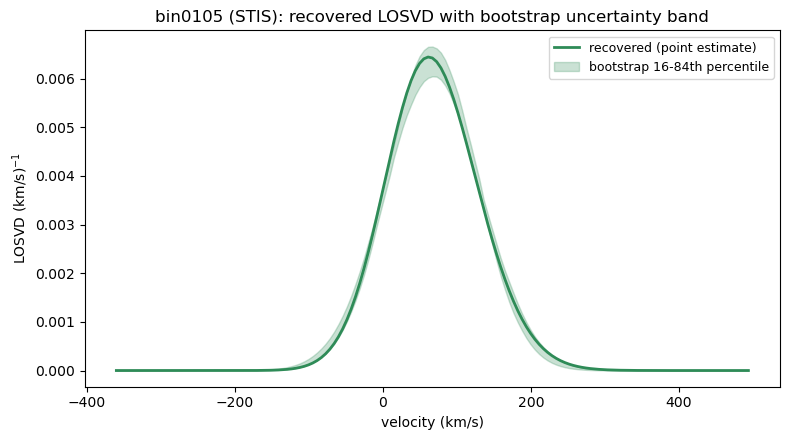

In [6]:
boot = bootstrap_losvd(A_stack_w, y_w, cfg, n_boot=30, seed=0)

print(f"V     = {moments['vherm']:+.1f} +/- {boot['vherm_std']:.1f} km/s")
print(f"sigma = {moments['sherm']:.1f} +/- {boot['sherm_std']:.1f} km/s")
print(f"h3    = {moments['h3']:+.4f} +/- {boot['h3_std']:.4f}")
print(f"h4    = {moments['h4']:+.4f} +/- {boot['h4_std']:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(v_grid, b_n, color='seagreen', lw=2.0, label='recovered (point estimate)')
ax.fill_between(v_grid, boot['b_p16'], boot['b_p84'],
                 color='seagreen', alpha=0.25, label='bootstrap 16-84th percentile')
ax.set_xlabel('velocity (km/s)'); ax.set_ylabel(r'LOSVD (km/s)$^{-1}$')
ax.set_title(f'{BINNAME} (STIS): recovered LOSVD with bootstrap uncertainty band')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


## Current limitations

- **`V`, `sigma`, and `h3` all disagree, stably, with
  `05_real_data_muse.ipynb`'s own result for the nominally-same nuclear
  aperture** -- demonstrated directly in Section 5, not assumed (a wider
  disagreement than an earlier version of this notebook found, since
  `05_real_data_muse.ipynb`'s own numbers changed under its rework).
  There is no independent ground truth to say which (if either) is
  closer to correct; treat this bin's own moments as provisional.
- **`lam_wing=0.0` (the default, unchanged in this notebook) is in
  exactly the regime `PARAMETER_GUIDE.md` flags as needing it tuned**
  (sigma~63, a real 50-template mixture, S/N~37) -- Section 5's
  `wing_mass` diagnostic and this bin's nonzero `h3`/asymmetric LOSVD are
  consistent with the same wing-amplitude-inflation mechanism
  `01_basic_mock_fit.ipynb`/`02_realistic_mock_fit.ipynb` demonstrate and
  correct on synthetic mocks with known truth. Not tuned here: there is
  no ground truth on real data to verify a chosen `lam_wing` value
  actually reduces bias rather than just moving the answer.
- **The regularization-bias correction is opt-in, not applied by default,
  and deliberately not demonstrated on this real bin.** Two distinct
  overcorrection failure modes were found under real testing on synthetic
  mocks with known truth, within the calibration's own nominal (MUSE,
  E-MILES) domain -- a real STIS template library at STIS pixel sampling
  is a further, untested extrapolation on top. Pass
  `apply_bias_correction=True` explicitly if you want to experiment with
  it, but do not treat its output as more trustworthy than the raw
  numbers above without independent validation.
- **Real data has no dedicated I/O loader in this package yet** -- this
  notebook reads a pre-extracted `.norm`/`.rms` ASCII format directly,
  matching `05_real_data_muse.ipynb`'s own convention.
- **Template subset is the library's full 50 stars**, not a principled
  selection -- see `04_template_calibration.ipynb` for the
  analogous MUSE/E-MILES diagnostic (not yet built for STIS).
- **One bin only**, the innermost -- STIS coverage of this target is
  sparser than MUSE's (fewer bins, lower S/N per bin at comparable
  radius), a real, instrument-driven data-quality difference, not a
  `kinextract` limitation.

See `05_real_data_muse.ipynb` for the same walkthrough on MUSE data (with
higher S/N and E-MILES templates instead), and `kinextract.
uncertainty`'s/`kinextract.bias_correction`'s own module docstrings
for the bootstrap design and regularization-bias correction.
